# Análisis de calidad de datos – Sismic Observer

## 1. Introducción

El objetivo de este análisis es evaluar la calidad de los datos sísmicos
almacenados en PostgreSQL dentro del proyecto Sismic Observer.

Para ello se analizarán los datos almacenados de USGS ya que tanto el contenido historico como el contenido en directo siguen las mismas normas de procesado.

Así mismo se analizarán los datos procedes de kafka y su tratamiento en el consumidor centrandonos tambien en el total de los datos recibidos ya que igual que ocurre en el productor tantos los eventos en directo como los historicos siguen la misma forma de procesamiento. Aquí además, los datos se enriquecen mediante el catálogo geográfico Natural Earth, que permite asignar cada terremoto a un país mediante operaciones espaciales.

Se evaluarán seis dimensiones de calidad:

1. Completitud.
2. Unicidad.
3. Validez.
4. Consistencia.
5. Actualidad.
6. Exactitud.

El análisis se realizará sobre los datos persistidos en PostgreSQL, sin modificar los registros originales.

Se distinguirán los valores ausentes, las anomalías y los registros rechazados o enviados a cuarentena.


### Origen de los datos
En primer lugar se analizarán las respuestas que se obtienen de consultar a USGS tanto en modo live como historico.

En ambos casos se recibe uan respuesta geojson con la siguiente estructura:

`{
    "type": "FeatureCollection",

    "metadata": {
        "generated": 1738368000000,
        "url": "https://earthquake.usgs.gov/fdsnws/event/1/query",
        "title": "USGS Earthquakes",
        "status": 200,
        "api": "1.14.0",
        "count": 2
    },

    "features": [
        {
            "type": "Feature",
            "properties": {
                "mag": 2.5,
                "place": "10km NW of Example",
                "time": 1735689600000,
                "updated": 1735689900000,
                "tz": null,
                "url": "https://earthquake.usgs.gov/earthquakes/eventpage/example",
                "detail": "https://earthquake.usgs.gov/fdsnws/event/1/query?eventid=example&format=geojson",
                "felt": null,
                "cdi": null,
                "mmi": null,
                "alert": null,
                "status": "reviewed",
                "tsunami": 0,
                "sig": 96,
                "net": "us",
                "code": "example",
                "ids": ",example,",
                "sources": ",us,",
                "types": ",origin,phase-data,",
                "nst": 20,
                "dmin": 0.5,
                "rms": 0.8,
                "gap": 120,
                "magType": "ml",
                "type": "earthquake",
                "title": "M 2.5 - 10km NW of Example"
            },
            "geometry": {
                "type": "Point",
                "coordinates": [
                    -115.123,
                    35.456,
                    8.5
                ]
            },
            "id": "example"
        }
    ],

    "bbox": [
        -115.123,
        35.456,
        8.5,
        -115.123,
        35.456,
        8.5
    ]
}`

Por lo que las transformaciones realizadas por el productor-live y el productor-replay cumplen con el mismo formato y en ambos casos se almacenará la misma información.

En segundo lugar se analizarán las tablas que componen la base de datos y la información que contienen.

In [4]:

import os
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from dotenv import load_dotenv

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Librerías cargadas correctamente")
print("Fecha del análisis:", datetime.now(timezone.utc))


Librerías cargadas correctamente
Fecha del análisis: 2026-11-16 18:07:54.415412+00:00


In [6]:
from IPython.display import display

# Conexión a PostgreSQL
DATABASE_URL = os.getenv("DATABASE_URL")

engine = create_engine(DATABASE_URL)

# Comprobar conexión
with engine.connect() as conn:
    result = conn.execute(text("SELECT version()"))
    print("Conexión establecida correctamente")
    print(result.scalar())


Conexión establecida correctamente
PostgreSQL 17.11 (Debian 17.11-1.pgdg13+2) on x86_64-pc-linux-gnu, compiled by gcc (Debian 14.2.0-19) 14.2.0, 64-bit


In [8]:
tables = [
    "raw_extractions",
    "ingestion_runs",
    "producer_event_state",
    "producer_event_exclusions",
    "countries",
    "earthquake_import_jobs",
    "earthquakes",
    "earthquake_versions",
    "consumer_quarantine"
]

# De forma general obtenemos una idea de la magnitud del contenido de las diversas tablas
for table in tables:
    query = text(f"SELECT COUNT(*) FROM {table}")

    with engine.connect() as conn:
        quantity = conn.execute(query).scalar()

    print(f"{table}: {quantity:,} registros")

raw_extractions: 710 registros
ingestion_runs: 712 registros
producer_event_state: 396,825 registros
producer_event_exclusions: 9,367 registros
countries: 177 registros
earthquake_import_jobs: 4 registros
earthquakes: 396,825 registros
earthquake_versions: 397,012 registros
consumer_quarantine: 0 registros


In [9]:
# Columnas de cada tabla
for table in tables:
    query = text(f"SELECT column_name, data_type, is_nullable, column_default FROM information_schema.columns WHERE table_name = :table")

    with engine.connect() as conn:
            columns = conn.execute(
                query,
                {"table": table}
            ).fetchall()
    
    print(f"\n{'=' * 60}")
    print(f"TABLA: {table}")
    print(f"{'=' * 60}")

    for column in columns:
        print(
            f"Columna: {column.column_name:<30} "
            f"Tipo: {column.data_type:<20} "
            f"Nullable: {column.is_nullable:<3} "
            f"Default: {column.column_default}"
        )

    print(f"\nTotal de columnas: {len(columns)}")



TABLA: raw_extractions
Columna: id                             Tipo: bigint               Nullable: NO  Default: nextval('raw_extractions_id_seq'::regclass)
Columna: sha256                         Tipo: character varying    Nullable: NO  Default: None
Columna: response_body                  Tipo: text                 Nullable: NO  Default: None
Columna: first_seen                     Tipo: timestamp with time zone Nullable: NO  Default: now()
Columna: last_seen                      Tipo: timestamp with time zone Nullable: NO  Default: now()
Columna: size_bytes                     Tipo: bigint               Nullable: NO  Default: None

Total de columnas: 6

TABLA: ingestion_runs
Columna: id                             Tipo: bigint               Nullable: NO  Default: nextval('ingestion_runs_id_seq'::regclass)
Columna: raw_extraction_id              Tipo: bigint               Nullable: YES Default: None
Columna: source                         Tipo: character varying    Nullable: NO  Def

#### Las tablas de los productores
Los productores interactuan con las siguientes tablas:
* raw_extractions: que se encarga de guardar la fuente original recibida. Contiene un SHA-256 unico para detectar respuestas repetidas y actualizar last_seen si esa respuesta ya ha sido guardada con anterioridad. De esta forma nos ahorramos guardar respuestas ya vistas.
* ingestion_runs: que se encarga de guardar las solicitudes de extraccion. Se relaciona con raw_extractions. Permite reconstruir cuando se recibio una extracción y su contenido
* producer_event_state: guarda para cada evento recibido su contenido y modo, de forma que si se recibe un evento varias veces pero no ha sido actualizado se descarta. Si que permite que un mismo evento pueda estar almacenado tanto en modo live como replay.
* producer_event_exclusions: se encarga de almacenar eventos omitidos indicando su motivo de exclusion. Los eventos descartados por el productor vienen aquí.

In [12]:
# Extraccion de datos para el analisis
query_raw = """
SELECT *
FROM raw_extractions
"""

raw = pd.read_sql(query_raw, engine)

print("Registros raw_extractions:", len(raw))
display(raw.head())

Registros raw_extractions: 356


,id,sha256,response_body,first_seen,last_seen,size_bytes
0,1,a21c067602e989d731ad416663a76f6c452b2e4c5b4161...,"{""type"":""FeatureCollection"",""metadata"":{""gener...",2026-11-14 16:02:17.739960+00:00,2026-11-14 16:02:17.739960+00:00,135597
1,2,8931e5e1399b1b83731f6163e5eca87aff82af1095fc57...,"{""type"":""FeatureCollection"",""metadata"":{""gener...",2026-11-14 16:03:17.752019+00:00,2026-11-14 16:03:17.752019+00:00,135597
2,3,7379130b0eff2f6a06ff47c5f4730aa4de2b07b9a8d4db...,"{""type"":""FeatureCollection"",""metadata"":{""gener...",2026-11-14 16:04:17.767262+00:00,2026-11-14 16:04:17.767262+00:00,135597
3,4,f7f5bd3562c68858c08c74c0bc2ed3d4bcf565eaf82f59...,"{""type"":""FeatureCollection"",""metadata"":{""gener...",2026-11-14 16:05:17.757462+00:00,2026-11-14 16:05:17.757462+00:00,135597
4,5,8001a0ce3febf23257e730b41b4bb86714dd0ae65b06ae...,"{""type"":""FeatureCollection"",""metadata"":{""gener...",2026-11-14 16:06:17.745852+00:00,2026-11-14 16:06:17.745852+00:00,134879


In [13]:
query_runs = """
SELECT *
FROM ingestion_runs
"""

runs = pd.read_sql(query_runs, engine)

print("Registros ingestion_runs:", len(runs))
display(runs.head())

Registros ingestion_runs: 357


,id,raw_extraction_id,source,request_url,requested_at,completed_at,http_status,status,records_received,error_message
0,1,1,USGS,https://earthquake.usgs.gov/earthquakes/feed/v...,2026-11-14 16:02:17.641107+00:00,2026-11-14 16:02:17.738570+00:00,200,success,190,None
1,2,2,USGS,https://earthquake.usgs.gov/earthquakes/feed/v...,2026-11-14 16:03:17.638592+00:00,2026-11-14 16:03:17.751147+00:00,200,success,190,None
2,3,3,USGS,https://earthquake.usgs.gov/earthquakes/feed/v...,2026-11-14 16:04:17.635587+00:00,2026-11-14 16:04:17.766620+00:00,200,success,190,None
3,4,4,USGS,https://earthquake.usgs.gov/earthquakes/feed/v...,2026-11-14 16:05:17.632881+00:00,2026-11-14 16:05:17.756189+00:00,200,success,190,None
4,5,5,USGS,https://earthquake.usgs.gov/earthquakes/feed/v...,2026-11-14 16:06:17.630082+00:00,2026-11-14 16:06:17.745079+00:00,200,success,189,None


In [14]:
query_state = """
SELECT *
FROM producer_event_state
"""

state = pd.read_sql(query_state, engine)

print("Eventos publicados:", len(state))
display(state.head())

Eventos publicados: 396433


,event_id,mode,last_published_updated_ms,last_payload_hash,last_published_at
0,aka2026wosyxm,live,1794672091388,d8f9a33c3e8034f6e884069b434651103c327389dd6450...,2026-11-14 16:02:17.901438+00:00
1,aka2026wosjlx,live,1794671046073,eeae7f96a11977a7ccb8c4689a829299ebaed1a749b7b4...,2026-11-14 16:02:17.908594+00:00
2,aka2026wosgwq,live,1794670846194,5af0bd35230fc2abc3fe6389e3d36a143dfe8a0db6b499...,2026-11-14 16:02:17.916376+00:00
3,ci41362095,live,1794670828453,594ea3ef6d21b4f0ebe609e99f06dab4ebc4c13dc88616...,2026-11-14 16:02:17.927456+00:00
4,ci41362087,live,1794670824306,c518837ede0021ea2c368dc4b58e0ec6cc405808aaaa80...,2026-11-14 16:02:17.933162+00:00


In [15]:
query_exclusions = """
SELECT *
FROM producer_event_exclusions
"""

exclusions = pd.read_sql(query_exclusions, engine)

print("Eventos excluidos:", len(exclusions))
display(exclusions.head())

Eventos excluidos: 9367


,id,event_id,mode,reason,raw_extraction_id,original_event,excluded_at
0,1,ci41361759,live,Tipo de evento no permitido: quarry blast,1,"{'id': 'ci41361759', 'type': 'Feature', 'geome...",2026-11-14 16:02:18.855954+00:00
1,2,mb90212658,live,Tipo de evento no permitido: quarry blast,1,"{'id': 'mb90212658', 'type': 'Feature', 'geome...",2026-11-14 16:02:18.875731+00:00
2,3,uw714138941,live,Tipo de evento no permitido: explosion,1,"{'id': 'uw714138941', 'type': 'Feature', 'geom...",2026-11-14 16:02:18.883335+00:00
3,40,ak0251nkqz1,replay,Tipo de evento no permitido: explosion,14,"{'id': 'ak0251nkqz1', 'type': 'Feature', 'geom...",2026-11-14 16:14:50.980717+00:00
4,41,ak0251sx89v,replay,Tipo de evento no permitido: ice quake,14,"{'id': 'ak0251sx89v', 'type': 'Feature', 'geom...",2026-11-14 16:14:51.786157+00:00


In [60]:
# Tambien necesitamos una tabla con los eventos geojson recibidos para comparar las 6 dimensiones de calidad
import json

features = []

def calculate_hash(data):
    serialized = json.dumps(
        data,
        sort_keys=True,
        ensure_ascii=False,
        separators=(",", ":")
    )

    return hashlib.sha256(
        serialized.encode("utf-8")
    ).hexdigest()


for _, row in raw.iterrows():

    geojson = json.loads(row["response_body"])

    for event in geojson.get("features", []):

        properties = event.get("properties", {})
        geometry = event.get("geometry") or {}

        coordinates = geometry.get("coordinates") or []

        features.append({
            "event_id": event.get("id"),
            "magnitude": properties.get("mag"),
            "place": properties.get("place"),
            "time": properties.get("time"),
            "updated": properties.get("updated"),
            "longitude": coordinates[0] if len(coordinates) > 0 else None,
            "latitude": coordinates[1] if len(coordinates) > 1 else None,
            "depth": coordinates[2] if len(coordinates) > 2 else None,
            "status": properties.get("status"),
            "type": properties.get("type"),
            "raw_id": row["id"],
            "hash": calculate_hash(event) if properties.get("type") == "earthquake" else None
        })

df_usgs = pd.DataFrame(features)

print("Eventos extraídos:", len(df_usgs))

display(df_usgs.head())

Eventos extraídos: 465818


,event_id,magnitude,place,time,updated,longitude,latitude,depth,status,type,raw_id,hash
0,aka2026wosyxm,1.50,"85 km NNW of Karluk, Alaska",1794672025461,1794672091388,-154.837000,58.306000,12.00,automatic,earthquake,1,d8f9a33c3e8034f6e884069b434651103c327389dd6450...
1,aka2026wosjlx,1.50,"101 km E of Cordova, Alaska",1794670956440,1794671046073,-143.919000,60.595000,28.10,automatic,earthquake,1,eeae7f96a11977a7ccb8c4689a829299ebaed1a749b7b4...
2,aka2026wosgwq,1.30,"45 km WNW of Valdez, Alaska",1794670777574,1794670846194,-147.167000,61.227000,5.00,automatic,earthquake,1,5af0bd35230fc2abc3fe6389e3d36a143dfe8a0db6b499...
3,nc75466397,1.28,"2 km NW of The Geysers, CA",1794670622420,1794671842734,-122.768669,38.789333,1.49,automatic,earthquake,1,8b695937080fee2c98c48b136fe8e3569bf19b7dcb861f...
4,ci41362095,2.44,"8 km W of Holtville, CA",1794670613660,1794670828453,-115.463170,32.816000,11.29,automatic,earthquake,1,594ea3ef6d21b4f0ebe609e99f06dab4ebc4c13dc88616...


In [42]:
# Conversion de las fechas a tipo fecha
df_usgs["time"] = pd.to_datetime(
    df_usgs["time"],
    unit="ms",
    utc=True,
    errors="coerce"
)

df_usgs["updated"] = pd.to_datetime(
    df_usgs["updated"],
    unit="ms",
    utc=True,
    errors="coerce"
)

raw["first_seen"] = pd.to_datetime(
    raw["first_seen"],
    utc=True
)

raw["last_seen"] = pd.to_datetime(
    raw["last_seen"],
    utc=True
)

runs["requested_at"] = pd.to_datetime(
    runs["requested_at"],
    utc=True
)

runs["completed_at"] = pd.to_datetime(
    runs["completed_at"],
    utc=True
)

state["last_published_at"] = pd.to_datetime(
    state["last_published_at"],
    utc=True
)

state["last_published_updated_ms"] = pd.to_datetime(
    state["last_published_updated_ms"],
    utc=True
)

exclusions["excluded_at"] = pd.to_datetime(
    exclusions["excluded_at"],
    utc=True
)

## Las 6 dimensiones de calidad del productor
Se va a evaluar en 3 niveles:
1. Calidad de los datos de entrada
2. Calidad del procesamiento
3. Calidad de los datos publicados

Las reglas a aplicar para cada dimensión serán:

Dimensión                        Indicadores que calcularemos

Exactitud                        Coincidencia de los mensajes publicados con el GeoJSON original.

Completitud                      Porcentaje de eventos con atributos obligatorios presentes.

Consistencia                     Coherencia entre identificadores, fechas, propiedades y modos.

Validez                          Cumplimiento de formatos, tipos y rangos permitidos.

Unicidad                         Eventos duplicados, revisiones repetidas y publicaciones innecesarias.

Oportunidad                      Tiempo entre actualización USGS, recepción y publicación.

### Completitud
Todos los campos necesarios para identificar un terremoto están presentes

Para ello deberán aparecer los campos
* event_id
* type
* updated_ms
* magnitud
* place
* time_ms
* longitud
* latitude
* depth

Para ello comprobaremos que los eventos originales obtenidos de USGS están completos

In [22]:
# Campos fundamentales para identificar y procesar un evento
critical_fields = ["event_id", "type", "updated"]

# Campos adicionales de información sísmica
information_fields = ["magnitude", "place", "time", "longitude", "latitude", "depth"]

df_usgs["critical_complete"] = (df_usgs[critical_fields].notna().all(axis=1)) # Campos criticos rellenos

df_usgs["information_complete"] = (df_usgs[information_fields].notna().all(axis=1)) # Campos información terremoto rellenos

completeness_critical = (df_usgs["critical_complete"].mean() * 100)

completeness_information = (df_usgs["information_complete"].mean() * 100)

print(f"Completitud crítica: {completeness_critical:.2f}%")
print(f"Completitud informativa: {completeness_information:.2f}%")

Completitud crítica: 100.00%
Completitud informativa: 99.99%


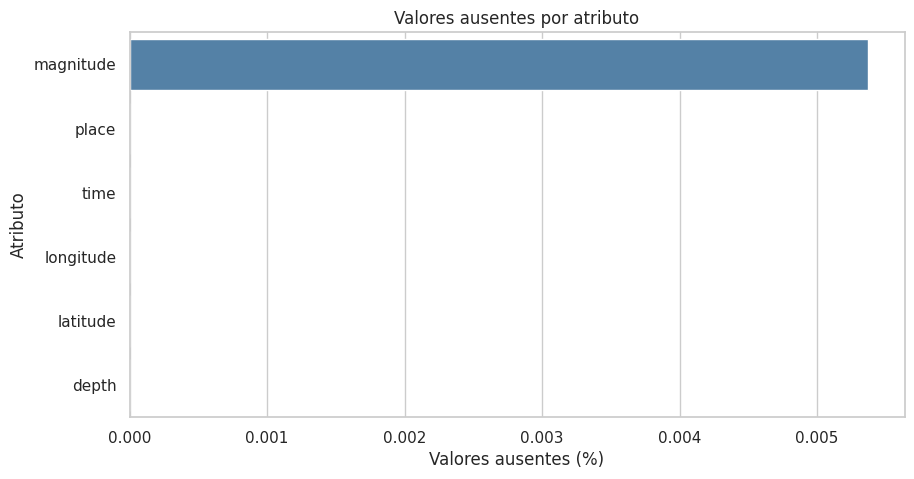

In [24]:
# Vamos a analizar en que campos informativos falta información
missing_percent = (
    df_usgs[information_fields]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index,
    color="steelblue"
)

plt.title("Valores ausentes por atributo")
plt.xlabel("Valores ausentes (%)")
plt.ylabel("Atributo")

plt.show()

Podemos ver que la calidad de la completitud es bastante alta en los datos informativos. Ya que el % de magnitudes faltantes es practicamente cero.

Por lo tanto podemos concluir que la completitud de los datos recibidos es muy buena, por lo que no habrá que hacer grandes labores del tratamiento de datos para completar los datos obtenidos.

### Exactitud
Como tenemos tanto el original como el contenido enviado a kafka podemos determinar la exactitud del procesamiento.

Para ello primero comprobaremos que el contenido original no ha cambiado con el almacenado


In [26]:
import hashlib
# Para ello calculamos el hash del response body que tenemos en raw, si este hash recalculado coincide 
# con el almacenado en hash256 de la tabla raw quiero decir que los datos se guardan con exactitud
def calculate_sha256(text):

    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


raw["calculated_hash"] = (
    raw["response_body"].apply(calculate_sha256)
)

raw["hash_correct"] = (
    raw["sha256"] == raw["calculated_hash"]
)

print(
    "Integridad de respuestas:",
    round(raw["hash_correct"].mean() * 100, 2),
    "%"
)

Integridad de respuestas: 100.0 %


Cual lo cual podemos concluir que los datos almacenados en su respuesta y en su sha son correctos al 100% y no hay discrepancias entre los datos recibidos. Esto es muy importante ya que se usa el sha para determinar si la respuesta ya sido vista antes y se puede omitir. Al asegurarnos la exactitud al 100% podemos asegurarnos que no hemos descartados respuesta que no habiamos visto antes

Ahora vamos a comprobar que exista exactitud entre los datos recibidos y los enviados. Para ello comprobaremos que el hash del payload de 


In [63]:
# Obtenemos solo los eventos de tipo terremotos originales
# Consistencia para los terremotos originales
usgs_earthquakes = df_usgs[
    df_usgs["type"] == "earthquake"
].copy()

audit = state.merge(
    usgs_earthquakes[["event_id", "hash"]],
    on="event_id",
    how="left"
)

audit["hash_match"] = (
    audit["last_payload_hash"] == audit["hash"]
)

In [64]:
# Eventos que tienen correspondencia en USGS
comparable = audit.dropna(subset=["hash"])

total = len(comparable)
coincidentes = comparable["hash_match"].sum()
diferentes = total - coincidentes

accuracy = (
    coincidentes / total * 100
    if total > 0 else 0
)

print(f"Eventos comparables: {total}")
print(f"Hashes coincidentes: {coincidentes}")
print(f"Hashes diferentes: {diferentes}")
print(f"Exactitud del payload: {accuracy:.2f}%")

Eventos comparables: 509526
Hashes coincidentes: 452600
Hashes diferentes: 56926
Exactitud del payload: 88.83%


Como vemos hay un porcentaje de terremotos que no coincide su payload con el del orginal, esto puede deberse a que han aparecido actualizaciones del terremoto despues de publicarse en kafka, o que al hacer el match de hash se esten comparando versiones distintas del mismo terremoto.

Seria conveniente estudiar a que se deben las discrepancias. Una forma de facilitar esta tarea y comprobar que no es debido al calculo de los hash seria añadir a la tabla producer_event_state un campo con el json original para poder comparar de forma directa el contenido.

### Consistencia
Aquí vamos a comprobar
* que updated no es anterior a time en los datos originales
* que todos los eventos son de tipo terremoto
* todas las exclusiones deben tener un motivo de exclusion
* first_seen es mayor a last_seen en raw
* completed_at es mayor que requested_at en runs

In [75]:
df_usgs["consistent_dates"] = (
    df_usgs["updated"] >= df_usgs["time"]
)

df_usgs["consistent_event"] = (
    (df_usgs["type"] == "earthquake")
)

consistency_checks = [
    "consistent_dates",
    "consistent_event"
]

consistency = (
    df_usgs[consistency_checks]
    .fillna(False)
    .all(axis=1)
    .mean() * 100
)

print(f"Consistencia global: {consistency:.2f}%")

Consistencia global: 97.86%


In [76]:

consistency_by_check = (
    df_usgs[consistency_checks]
    .fillna(False)
    .mean()
    .mul(100)
    .round(2)
)

print("Consistencia por validación:")

for check, percentage in consistency_by_check.items():
    print(f"{check}: {percentage:.2f}%")

Consistencia por validación:
consistent_dates: 100.00%
consistent_event: 97.86%


Como vemos la consistencia de los datos recibidos es bastante grande. La principal fuente de incosistencia en estos datos se produce porque desde usgs nos llegan no solo terremotos sino tambien explosiones de canteras, roturas de hielo... y más que producen lecturas en los sensores sismicos pero no se catalogan de terremotos, por eso podemos ver que el evento es la principal fuente de inconsistencia. Pero estos son desachados por el productor a la tabla de exclusions

In [78]:
# Consitencia para raw
raw["consistent_dates"] = (
    raw["last_seen"] >= raw["first_seen"]
)

consistency_raw = (
    raw["consistent_dates"]
    .mean() * 100
)

print(f"Consistencia raw: {consistency_raw:.2f}%")

Consistencia raw: 100.00%


Todas las respuestas originales estan bien actulizadas y contabilizadas

In [79]:
# Razones validas en exlusions
valid_reasons = [
    "Evento con estructura inválida",
    "Identificador ausente",
    "Propiedades del evento inválidas",
]

exclusions["reason_check"] = (
    exclusions["reason"].isin(valid_reasons)
    |
    exclusions["reason"].str.startswith(
        "Tipo de evento no permitido:",
        na=False
    )
)

consistency_exclusions = (
    exclusions["reason_check"]
    .mean() * 100
)

print(f"Consistencia exclusiones: {consistency_exclusions:.2f}%")

Consistencia exclusiones: 100.00%


Todos los eventos excluidos tienen un motivo de exclusion valido segun nuestras reglas de negocio del productor

In [107]:
# Consitencia para raw
runs["consistent_dates"] = (
    runs["completed_at"] >= runs["requested_at"]
)

consistency_runs = (
    runs["consistent_dates"]
    .mean() * 100
)

print(f"Consistencia runs: {consistency_runs:.2f}%")

Consistencia runs: 100.00%


Podemos comprobar que las ejecuciones de extraccion se actualizan correctamente sus tiempos de finalizacion

In [109]:
consistency_mean=(consistency_runs+consistency_exclusions+consistency_raw+consistency)/4

### Validez
Comprobaremos ahora que los datos recibidos cumplen el formato y valores maximos y minimos para cada caso


In [86]:
df_usgs["valid_event_id"] = (
    df_usgs["event_id"].apply(
        lambda x: isinstance(x, str) and len(x.strip()) > 0
    )
)

df_usgs["valid_magnitude"] = (
    pd.to_numeric(
        df_usgs["magnitude"],
        errors="coerce"
    ).notna()
    &
    df_usgs["magnitude"].between(-2, 10, inclusive="both")
)

df_usgs["valid_longitude"] = (
    df_usgs["longitude"].between(-180, 180)
)

df_usgs["valid_latitude"] = (
    df_usgs["latitude"].between(-90, 90)
)

df_usgs["valid_depth"] = (
    df_usgs["depth"].between(-100, 1000)
)

df_usgs["valid_updated"] = (
    pd.to_numeric(
        df_usgs["updated"],
        errors="coerce"
    ).notna()
    &
    df_usgs["updated"].ge(0)
)

validity_checks = [
    "valid_event_id",
    "valid_magnitude",
    "valid_longitude",
    "valid_latitude",
    "valid_depth",
    "valid_updated"
]

validity = (
    df_usgs[validity_checks]
    .fillna(False)
    .all(axis=1)
    .mean() * 100
)

print(f"Validez global: {validity:.2f}%")

validity_by_parameter = (
    df_usgs[validity_checks]
    .fillna(False)
    .mean()
    .mul(100)
    .round(2)
)

for parameter, percentage in validity_by_parameter.items():
    print(f"{parameter}: {percentage:.2f}%")

Validez global: 99.99%
valid_event_id: 100.00%
valid_magnitude: 99.99%
valid_longitude: 100.00%
valid_latitude: 100.00%
valid_depth: 100.00%
valid_updated: 100.00%


El valor obtenido esta comprobacion de validez esta estrechamente relacionado con el valor al analizar la completitud y probablemente se deba al mismo motivo

### Unicidad
Este parametro es especialmente interesante de analizar en nuestro caso para comprobar que en efecto no se estan publicando versiones repetidas de eventos en cada extraccion

In [88]:
valid_ids = df_usgs[df_usgs["event_id"].notna()].copy()

duplicate_events = valid_ids.duplicated(
    subset=["raw_id", "event_id"],
    keep="first"
)

uniqueness = (
    1 - duplicate_events.mean()
) * 100

print(f"Unicidad por extracción: {uniqueness:.2f}%")

Unicidad por extracción: 100.00%


In [90]:
revisions = (
    valid_ids.groupby("event_id")
    .agg(
        appearances=("raw_id", "count"),
        extractions=("raw_id", "nunique"),
        versions=("updated", "nunique")
    )
    .reset_index()
)

print("Eventos con varias versiones:")

display(
    revisions[revisions["versions"] > 1]
    .sort_values("versions", ascending=False)
    .head(10)
)

Eventos con varias versiones:


,event_id,appearances,extractions,versions
405545,uw714139181,266,266,9
158288,ci41362151,217,217,7
158286,ci41362135,232,232,4
158280,ci41362071,321,321,4
381384,us7000tyek,55,55,4
392889,uu80164656,55,55,4
158265,ci41361951,266,266,3
158263,ci41361935,266,266,3
158287,ci41362143,218,218,3
158289,ci41362159,172,172,3


Tambien comprobaremos la unicidad de los eventos publicados en kafka, ya que no deben aparecer mas de una vez con el mismo event_id, payload y mode

In [93]:
unique_columns = [
    "event_id",
    "mode",
    "last_payload_hash"
]

state["valid_uniqueness"] = (
    ~state.duplicated(
        subset=unique_columns,
        keep=False
    )
)

uniqueness = (
    state["valid_uniqueness"]
    .mean() * 100
)

print(f"Unicidad: {uniqueness:.2f}%")


Unicidad: 100.00%


Tambien comprobaremos la unicidad de los eventos excluidos ya que si un evento ha sido excluido por un motivo no puede volver a aparecer

In [96]:
unique_columns = [
    "event_id",
    "mode"
]

exclusions["valid_uniqueness"] = (
    ~exclusions.duplicated(
        subset=unique_columns,
        keep=False
    )
)

uniqueness_exclusions = (
    exclusions["valid_uniqueness"]
    .mean() * 100
)

print(
    f"Unicidad exclusiones: {uniqueness_exclusions:.2f}%"
)

Unicidad exclusiones: 100.00%


In [112]:
uniqueness_mean=(uniqueness_exclusions+uniqueness)/2

### Oportunidad
En el sistema calculamos tanto la duracion de las extracciones como el retraso entre la actualizacion del terremoto y la publicacion

In [101]:
runs["extraction_seconds"] = (
    runs["completed_at"] -
    runs["requested_at"]
).dt.total_seconds()

mean_duration = runs["extraction_seconds"].mean()

print(f"Duración media de las extracciones: {mean_duration:.2f} segundos")

top_3 = (
    runs.dropna(subset=["extraction_seconds"])
    .nlargest(3, "extraction_seconds")
)

display(
    top_3[
        [
            "id",
            "requested_at",
            "completed_at",
            "extraction_seconds",
            "status",
            "http_status",
            "records_received"
        ]
    ]
)


Duración media de las extracciones: 13.26 segundos


,id,requested_at,completed_at,extraction_seconds,status,http_status,records_received
234,235,2026-11-14 19:21:18.301293+00:00,2026-11-14 20:38:34.062201+00:00,4635.760908,success,200,189
145,146,2026-11-14 17:59:00.284690+00:00,2026-11-14 17:59:02.507275+00:00,2.222585,success,200,12124
17,18,2026-11-14 16:16:30.897010+00:00,2026-11-14 16:16:32.952929+00:00,2.055919,success,200,11861


Con el top 3 podemos ver como hay extracciones mucho más largas que la media, probablemente se trata de extracciones de tipo replay con un periodo grande de tiempo.
Podria ser interesante añadir a la tabla raw un campo de modo para saber si en efecto estas importaciones se deben a importaciones historicas

In [103]:
duplicados = runs["raw_extraction_id"].duplicated(keep=False)

print("¿Existen raw_extraction_id repetidos?:", duplicados.any())

print("Número de ejecuciones con raw_extraction_id repetido:",
      duplicados.sum())

¿Existen raw_extraction_id repetidos?: True
Número de ejecuciones con raw_extraction_id repetido: 2


In [104]:
repeated_runs = (
    runs[runs["raw_extraction_id"].duplicated(keep=False)]
    .sort_values("raw_extraction_id")
)

display(repeated_runs)

,id,raw_extraction_id,source,request_url,requested_at,completed_at,http_status,status,records_received,error_message,consistent_dates,extraction_seconds
234,235,235,USGS,https://earthquake.usgs.gov/earthquakes/feed/v...,2026-11-14 19:21:18.301293+00:00,2026-11-14 20:38:34.062201+00:00,200,success,189,None,True,4635.760908
235,236,235,USGS,https://earthquake.usgs.gov/earthquakes/feed/v...,2026-11-14 20:39:30.612630+00:00,2026-11-14 20:39:31.099869+00:00,200,success,189,None,True,0.487239


In [106]:
raw_235 = raw[raw["id"] == 235]

display(raw_235)

,id,sha256,response_body,first_seen,last_seen,size_bytes,calculated_hash,hash_correct,consistent_dates
234,235,54f8d763bc314fe5fabb0674d9e901b4d8f42a0b9ff01a...,"{""type"":""FeatureCollection"",""metadata"":{""gener...",2026-11-14 20:38:34.063732+00:00,2026-11-14 20:39:31.101471+00:00,135030,54f8d763bc314fe5fabb0674d9e901b4d8f42a0b9ff01a...,True,True


Tambien podria deberse estas extracciones que tarda más a extracciones que fallan y deben ser reintentadas. Por eso de nuevo seria interesante guardar si se trata de una extraccion replay o live. Para poder distinguir si son casos en los que pueda fallar el servicio de USGS o son casos de importaciones grandes o reanudadas

In [116]:
# Tiempo máximo esperado en segundos
MAX_TIME = 5

# Porcentaje de ejecuciones que cumplen el objetivo
opportunity = (
    (runs["extraction_seconds"] <= MAX_TIME).mean() * 100
)

print(f"Oportunidad: {opportunity:.2f}%")

Oportunidad: 99.72%


Podemos ver como el sistema es bastante rapido no perdemos tiempo al ejecutar las extracciones en general, cuanto mas tardese el sistema en ejecutarlas podria haber problema de encolacion de importaciones, especialmente critico en el caso de muchos usuarios pediendo diferentes importaciones.

### Resumen de calidad del productor

In [118]:
quality_results = pd.DataFrame({

    "Dimensión": [
        "Exactitud",
        "Completitud",
        "Consistencia",
        "Validez",
        "Unicidad",
        "Oportunidad"
    ],

    "Resultado (%)": [
        accuracy,
        completeness_information,
        consistency_mean,
        validity.mean(),
        uniqueness_mean,
        opportunity,
    ]

})

def classify_quality(value):

    if value >= 98:
        return "Excelente"

    elif value >= 95:
        return "Bueno"

    elif value >= 90:
        return "Aceptable"

    elif value >= 80:
        return "Deficiente"

    else:
        return "Crítico"


global_quality = quality_results["Resultado (%)"].mean()

global_classification = classify_quality(global_quality)

print(f"Calidad global: {global_quality:.2f}%")
print(f"Clasificación: {global_classification}")

quality_results["Resultado (%)"] = (
    quality_results["Resultado (%)"].round(2)
)

display(
    quality_results.style
    .format({"Resultado (%)": "{:.2f}%"})
    .background_gradient(
        subset=["Resultado (%)"],
        cmap="RdYlGn",
        vmin=0,
        vmax=100
    )
    .set_caption("Resumen global de calidad de datos")
)


Calidad global: 98.00%
Clasificación: Bueno


,Dimensión,Resultado (%)
0,Exactitud,88.83%
1,Completitud,99.99%
2,Consistencia,99.47%
3,Validez,99.99%
4,Unicidad,100.00%
5,Oportunidad,99.72%


En resumen la aplicacion del productor presenta muy buenos resultados.

De especial atencion resulta los datos de exactitud ya que a priori parece haber discrepancias entre lo que obtenemos y lo que publicamos en algunos casos. En ese caso seria interesante como se ha comentado previamente añadir el json original a la tabla producer_event_state para poder comparar de forma más directa el contenido entre los que recibimos desde USGS y lo que enviamos, ya que ahora mismo solo se comparan los payload y puede haber discrepancias entre los eventos que se estan comparando asi como en la forma en las que estan formateados ambos payload antes de hacerse el sha, lo cual puede dar lugar a sha diferentes aunque el contenido sea el mismo.

Así mismo aunque ahora mismo el analisis de oportunidad es muy bueno hay que tener especial cuidado en el posible encolamiento de peticiones de importacion muy grandes ya que podria paralizar el sistema durante mucho tiempo retrasando otras importaciones historicas y live, ya que solo se permite una runs en estado running a la vez para evitar sobreescrituras con eventos antiguos que puedan llegar despues de otras importaciones. Por ello sería interesante tambien conocer si la ingesta asociada a un run es debiado a un replay o a un live de modo que podriamos separar ambos origenes y comprobar si las importaciones replay necesitan limitarse en tamaño ya que actualmente no hay limite de periodos. Tambien serviria para conocer los tiempos de disponibilidades de USGS ya que si las peticiones live pasan a tener tiempos cada vez mayores podria ser necesario buscar otros proveedores de esta información o para determinar caidas de USGS ajenas a nuestro servicio.


### Analisis de los eventos rechazados por el productor

In [120]:
exclusion_summary = (
    exclusions
    .groupby("reason")
    .size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
)

print(exclusion_summary)

                                               reason  records
10          Tipo de evento no permitido: quarry blast     4347
3              Tipo de evento no permitido: explosion     2785
4              Tipo de evento no permitido: ice quake     1363
8       Tipo de evento no permitido: mining explosion      578
9            Tipo de evento no permitido: other event      236
5              Tipo de evento no permitido: landslide       41
12            Tipo de evento no permitido: sonic boom        5
7          Tipo de evento no permitido: mine collapse        3
2   Tipo de evento no permitido: experimental expl...        3
6              Tipo de evento no permitido: meteorite        2
0   Tipo de evento no permitido: accidental explosion        1
1     Tipo de evento no permitido: chemical explosion        1
11             Tipo de evento no permitido: rockslide        1
13     Tipo de evento no permitido: volcanic eruption        1


In [122]:
total_received = len(df_usgs) + len(exclusions)

exclusion_percentage = (
    len(exclusions) / total_received * 100
    if total_received > 0 else 0
)

print(f"Porcentaje de exclusiones: {exclusion_percentage:.2f}%")

Porcentaje de exclusiones: 1.97%


Como vemos el porcentaje de exclusiones es muy pequeño y en general funciona bien de forma automatica, descartando todos aquellos eventos que no son terremotos. Ya que a nuestra aplicación no le interesan estos eventos, de esta forma la tabla de terremotos solo contienen los eventos que nos interesa.

De nuestro analisis de completitud encontramos que algunos registros carecian de magnitud pero aqui no aparecen excluidos por lo que seria interesante a futuro añadir esa condicion a nuestro fichero de extractions, ya que parece ser que de momento se estan publicando esos eventos en kafka. Lo cual cuanto más se deje así mas registros podemos acabar teniendo que arreglar en la base de datos, bien para extraerlos definitivamente o bien para darles un valor por defecto o buscar otras fuentes que rellenen ese campo de forma automatica, lo cual puede suponer un coste adicional.

### Acciones de limpieza y mejoras

En cuanto a las tablas de gestiona nuestro productor no sería necesario tomar ninguna accion de limpieza, tan solo sería analizar los payloads pero para ello lo mejor sería cambiar la estructura de algunas de las tablas implicadas como se ha expuesto anteriormente.

Tambien añadir campos adicionales en raw para mejorar la trazabilidad y el analisis de oportunidad asi como mejorar los requisitos de exclusion de nuestras exclusiones del productor para hacerlas mas duras, de forma que no lleguen al consumidor eventos incorrectos, ya que el consumidor al tener tareas de enriquecimiento de datos sus operaciones sobre los datos son mas costosas. En cualquier caso cuando a continuacion analicemos el consumidor y la calidad de los datos publicados podremos ver si las restricciones de validacion de los datos estan sirviendo de frenos a casos como los eventos sin magnitud.

## Las 6 dimensiones de calidad del consumidor
Se va a evaluar en 3 niveles:
1. Calidad de los datos de entrada
2. Calidad del procesamiento
3. Calidad de los datos publicados

Las reglas a aplicar para cada dimensión serán:

Dimensión                        Indicadores que calcularemos

Exactitud                        Coincidencia de los mensajes publicados con el GeoJSON original.

Completitud                      Porcentaje de eventos con atributos obligatorios presentes.

Consistencia                     Coherencia entre identificadores, fechas, propiedades y modos.

Validez                          Cumplimiento de formatos, tipos y rangos permitidos.

Unicidad                         Eventos duplicados, revisiones repetidas y publicaciones innecesarias.

Oportunidad                      Tiempo entre actualización USGS, recepción y publicación.

### Completitud
Comprobaremos que % de terremotos tiene todos sus campos obligatorios rellenos
* event_id
* mode
* source
* longitude
* latitude
* event_time
* updated
* ingested_at

Son los campos que consideraremos obligatorios.
Las tablas que emplea el consumidor son las siguientes:
* earthquakes: donde se guarda la información actual de todos los terremotos
* countries: donde se guarda la informacion de paises procendente de Natural Earth para el enriquecimiento de los datos de USGS
* earthquake_versions: donde se guarda cada version que llega del terremoto
* consumer_quarantine: aqui se guardan los registros que no superan la validación

In [7]:
query_earthquakes = """
SELECT *
FROM earthquakes
"""

query_versions = """
SELECT *
FROM earthquake_versions
"""

query_countries = """
SELECT *
FROM countries
"""

with engine.connect() as conn:

    earthquakes = pd.read_sql(
        text(query_earthquakes), conn
    )

    versions = pd.read_sql(
        text(query_versions), conn
    )

    countries = pd.read_sql(
        text(query_countries), conn
    )

print("Terremotos:", len(earthquakes))
print("Versiones:", len(versions))
print("Países:", len(countries))

Terremotos: 396844
Versiones: 397053
Países: 177


In [9]:
display(earthquakes.head())
display(earthquakes.info())

,event_id,mode,source,magnitude,magnitude_type,event_type,place,longitude,latitude,depth_km,event_time,updated,updated_ms,ingested_at,processed_at,country_code
0,aka2026wosyxm,live,USGS,1.50,ml,earthquake,"85 km NNW of Karluk, Alaska",-154.83700,58.30600,12.00,2026-11-14 16:00:25.461000+00:00,2026-11-14 16:01:31.388000+00:00,1794672091388,2026-11-14 16:02:17.757320+00:00,2026-11-14 16:02:19.325909+00:00,USA
1,aka2026wosgwq,live,USGS,1.30,ml,earthquake,"45 km WNW of Valdez, Alaska",-147.16700,61.22700,5.00,2026-11-14 15:39:37.574000+00:00,2026-11-14 15:40:46.194000+00:00,1794670846194,2026-11-14 16:02:17.911214+00:00,2026-11-14 16:02:19.349730+00:00,USA
2,aka2026wopmcq,live,USGS,0.50,ml,earthquake,"58 km WNW of Tyonek, Alaska",-152.18800,61.21200,3.70,2026-11-14 14:15:42.357000+00:00,2026-11-14 14:16:26.061000+00:00,1794665786061,2026-11-14 16:02:17.992586+00:00,2026-11-14 16:02:19.385308+00:00,USA
3,ci41362031,live,USGS,0.94,ml,earthquake,"7 km SSW of Devore, CA",-117.43183,34.16117,5.99,2026-11-14 14:10:06.460000+00:00,2026-11-14 14:13:37.266000+00:00,1794665617266,2026-11-14 16:02:17.999117+00:00,2026-11-14 16:02:19.397990+00:00,USA
4,aka2026wonrfz,live,USGS,0.40,ml,earthquake,"61 km ENE of Pedro Bay, Alaska",-153.13200,60.04500,5.00,2026-11-14 13:21:38.841000+00:00,2026-11-14 13:24:25.133000+00:00,1794662665133,2026-11-14 16:02:18.031867+00:00,2026-11-14 16:02:19.411648+00:00,USA


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 396844 entries, 0 to 396843
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype              
---  ------          --------------   -----              
 0   event_id        396844 non-null  object             
 1   mode            396844 non-null  object             
 2   source          396844 non-null  object             
 3   magnitude       396823 non-null  float64            
 4   magnitude_type  396823 non-null  object             
 5   event_type      396844 non-null  object             
 6   place           396844 non-null  object             
 7   longitude       396844 non-null  float64            
 8   latitude        396844 non-null  float64            
 9   depth_km        396844 non-null  float64            
 10  event_time      396844 non-null  datetime64[ns, UTC]
 11  updated         396844 non-null  datetime64[ns, UTC]
 12  updated_ms      396844 non-null  int64              
 13  ingested_at   

None

Ademas de comprobar los campos aleatorios tambien analizaremos si que porcentaje de campos nulables tenemos efectivamente nulos. Lo cual podria ser interesante para eliminar dichas columnas

In [11]:
required_fields = [
    "event_id",
    "mode",
    "source",
    "longitude",
    "latitude",
    "event_time",
    "updated",
    "ingested_at"
]

earthquakes["completitud_estructural"] = (
    earthquakes[required_fields]
    .notna()
    .all(axis=1)
)

optional_fields = [
    "magnitude",
    "magnitude_type",
    "place",
    "depth_km"
]

all_fields = required_fields+optional_fields
completeness = pd.DataFrame({
    "Campo": all_fields,
    "Tipo": [
        "Estructural" if campo in required_fields else "Descriptivo"
        for campo in all_fields
    ],
    "Completitud (%)": [
        earthquakes[campo].notna().mean() * 100
        for campo in all_fields
    ]
})

# Mostrar resultados
display(
    completeness.round(2)
    .sort_values("Completitud (%)", ascending=True)
    .reset_index(drop=True)
)

,Campo,Tipo,Completitud (%)
0,magnitude_type,Descriptivo,99.99
1,magnitude,Descriptivo,99.99
2,event_id,Estructural,100.00
3,mode,Estructural,100.00
4,latitude,Estructural,100.00
5,event_time,Estructural,100.00
6,source,Estructural,100.00
7,longitude,Estructural,100.00
8,ingested_at,Estructural,100.00
9,updated,Estructural,100.00


Como vemos el valor de completitud coincide con el los obtenidos en el productor, ya que el % faltante es en la misma magnitud.

Por lo tanto el consumidor esta tratando a nivel de completitud correctamente los datos recibidos.

### Exactitud
Comprobaremos que los datos transformados son iguales a los obtenidos del mensaje de kafka. Compararemos
* event_id
* mode
* magnitude
* latitude
* longitude
* depth

In [12]:
# Obtenemos los mensajes originales en un dataframe

import json

def obtener_original(valor):

    if isinstance(valor, dict):
        return valor

    if isinstance(valor, str):
        try:
            return json.loads(valor)
        except (json.JSONDecodeError, TypeError):
            return None

    return None


versions["original_message"] = (
    versions["original_message"].apply(obtener_original)
)


# Unimos los registros originales con los datos procesados

accuracy = earthquakes.merge(
    versions,
    on=["event_id", "mode", "updated_ms"],
    how="left",
    suffixes=("", "_version")
)

print("Registros comparables:", accuracy["original_message"].notna().sum())
print("Registros totales:", len(accuracy))

Registros comparables: 396844
Registros totales: 396844


In [13]:
# Compareremos los campos de forma independiente y luego determinaremos la exactitud global del registros
def comparar_original(row):

    original = row["original_message"]

    if not isinstance(original, dict):
        return None

    event = original.get("event", {})
    properties = event.get("properties", {})
    geometry = event.get("geometry", {})

    coordinates = geometry.get("coordinates", [])

    if not isinstance(coordinates, (list, tuple)) or len(coordinates) != 3:
        return None

    comparisons = {}

    # Identificador
    comparisons["event_id"] = (
        event.get("id") == row["event_id"]
    )

    # Modo y fuente
    comparisons["mode"] = (
        original.get("mode") == row["mode"]
    )

    comparisons["source"] = (
        original.get("source") == row["source"]
    )

    # Coordenadas
    comparisons["longitude"] = np.isclose(
        float(coordinates[0]),
        row["longitude"],
        rtol=1e-9,
        atol=1e-9
    )

    comparisons["latitude"] = np.isclose(
        float(coordinates[1]),
        row["latitude"],
        rtol=1e-9,
        atol=1e-9
    )

    # Profundidad
    depth_original = coordinates[2]
    depth_actual = row["depth_km"]

    if depth_original is None or pd.isna(depth_actual):
        comparisons["depth_km"] = (
            depth_original is None and pd.isna(depth_actual)
        )
    else:
        comparisons["depth_km"] = np.isclose(
            float(depth_original),
            depth_actual,
            rtol=1e-9,
            atol=1e-9
        )

    # Magnitud
    mag_original = properties.get("mag")
    mag_actual = row["magnitude"]

    if mag_original is None or pd.isna(mag_actual):
        comparisons["magnitude"] = (
            mag_original is None and pd.isna(mag_actual)
        )
    else:
        comparisons["magnitude"] = np.isclose(
            float(mag_original),
            mag_actual,
            rtol=1e-9,
            atol=1e-9
        )

    # Fechas
    comparisons["event_time"] = (
        properties.get("time") == int(
            row["event_time"].timestamp() * 1000
        )
    )

    comparisons["updated"] = (
        properties.get("updated") == int(
            row["updated"].timestamp() * 1000
        )
    )

    return comparisons

In [18]:
accuracy["comparaciones"] = accuracy.apply(
    comparar_original,
    axis=1
)


# Extraemos los resultados de cada campo

accuracy_fields = [
    "event_id",
    "mode",
    "source",
    "longitude",
    "latitude",
    "depth_km",
    "magnitude",
    "event_time",
    "updated"
]

for field in accuracy_fields:

    accuracy[f"exactitud_{field}"] = (
        accuracy["comparaciones"].apply(
            lambda x: x.get(field, np.nan)
            if isinstance(x, dict)
            else np.nan
        )
    )


# Exactitud global del registro

accuracy["registro_exacto"] = (
    accuracy[
        [f"exactitud_{field}" for field in accuracy_fields]
    ]
    .eq(True)
    .all(axis=1)
)


# Identificamos registros comparables

registros_comparables = (
    accuracy["comparaciones"].apply(
        lambda x: isinstance(x, dict)
    )
)

print("Registros comparables:", registros_comparables.sum())


# Calculamos exactitud global

accuracy_note = (
    accuracy.loc[
        registros_comparables,
        "registro_exacto"
    ].mean() * 100
)

print(f"Exactitud global: {accuracy_note:.2f}%")

Registros comparables: 396844
Exactitud global: 100.00%


In [19]:

# Calculamos la exactitud individual por campo

exactitud_campos = pd.DataFrame({
    "Campo": accuracy_fields,
    "Exactitud (%)": [
        accuracy.loc[
            accuracy[f"exactitud_{field}"].notna(),
            f"exactitud_{field}"
        ].mean() * 100
        for field in accuracy_fields
    ],
    "Registros comparados": [
        accuracy[f"exactitud_{field}"].notna().sum()
        for field in accuracy_fields
    ]
})

display(exactitud_campos.round(2))


,Campo,Exactitud (%),Registros comparados
0,event_id,100.0,396844
1,mode,100.0,396844
2,source,100.0,396844
3,longitude,100.0,396844
4,latitude,100.0,396844
5,depth_km,100.0,396844
6,magnitude,100.0,396844
7,event_time,100.0,396844
8,updated,100.0,396844


Podemos ver que durante el proceso de transformación los datos se mantienen invariables

### Consistencia
En nuestro caso concreto comprobaremos la consistencia de las siguiente variables:
* updated > event_time
* processed_at > ingested_at
* country_code debe estar presente en el catalogo de paises

In [22]:
consistency = pd.DataFrame(index=earthquakes.index)

consistency["consistencia_temporal_evento"] = (
    earthquakes["updated"]
    >= earthquakes["event_time"]
)

consistency["consistencia_temporal_procesamiento"] = (
    earthquakes["processed_at"]
    >= earthquakes["ingested_at"]
)

valid_codes = set(countries["adm0_a3"].dropna())

consistency["consistencia_geografica"] = (
    earthquakes["country_code"].isna()
    | earthquakes["country_code"].isin(valid_codes)
)

earthquakes["registro_consistente"] = (
    consistency.all(axis=1)
)

In [31]:
consistency_result = (
    consistency.mean()
    .mul(100)
    .rename("porcentaje_consistencia")
    .to_frame()
)

consistency_result.loc["GLOBAL"] = (
    earthquakes["registro_consistente"].mean() * 100
)

display(consistency_result.round(2))

,porcentaje_consistencia
consistencia_temporal_evento,100.00
consistencia_temporal_procesamiento,99.98
consistencia_geografica,100.00
GLOBAL,99.98


In [23]:
inconsistencias_procesamiento = earthquakes[
    ~consistency["consistencia_temporal_procesamiento"]
]

display(
    inconsistencias_procesamiento[
        ["ingested_at", "processed_at"]
    ]
)

numero_inconsistencias = (
    (~consistency["consistencia_temporal_procesamiento"]).sum()
)

print("Número de filas inconsistentes:", numero_inconsistencias)

,ingested_at,processed_at
39,2026-11-14 17:36:17.596702+00:00,2026-11-14 16:02:19.569723+00:00
40,2026-11-14 17:38:17.550785+00:00,2026-11-14 16:02:19.361292+00:00
158,2026-11-14 17:31:17.594033+00:00,2026-11-14 16:02:20.922957+00:00
159,2026-11-14 17:36:17.593073+00:00,2026-11-14 16:02:20.932976+00:00
160,2026-11-14 17:36:17.600230+00:00,2026-11-14 16:02:20.941700+00:00
183,2026-11-14 16:13:17.746532+00:00,2026-11-14 16:02:20.710695+00:00
198168,2026-11-14 16:29:17.751688+00:00,2026-11-14 16:27:17.700788+00:00
257828,2026-11-14 16:45:17.692316+00:00,2026-11-14 16:02:20.961329+00:00
257831,2026-11-14 16:53:17.679336+00:00,2026-11-14 16:25:17.716149+00:00
257833,2026-11-14 17:32:17.578295+00:00,2026-11-14 16:02:19.373250+00:00


Número de filas inconsistentes: 100


Esta incosistencia puede deberse a diversos motivos, como son pocos en comparacion al total es poco probable que se deba a errores en el registro de datos. Entre las opciones más posibles creo que estan retrasos en el proceso de ingesta, que puede hacer que las operaciones no queden registradas en el orden correcto o problemas de actualización, de modo que al actualziarse los datos de esos registros no se hayan registrado correctamente las fechas

### Validez
En este caso analizaremos que los datos almacenados cumplen las reglas de validez del consumidor 

Las reglas principales serán:
* Longitud entre -180 y 180.
* Latitud entre -90 y 90.
* Magnitud numérica y finita, cuando existe.
* Profundidad numérica y finita, cuando existe.
* Modo perteneciente a live o replay.
* Identificador y fuente no vacíos.
* Fechas presentes y correctamente interpretadas.

In [24]:
validity = pd.DataFrame(index=earthquakes.index)

# Coordenadas
validity["longitud"] = (
    earthquakes["longitude"].between(-180, 180)
)

validity["latitud"] = (
    earthquakes["latitude"].between(-90, 90)
)

# Valores numéricos finitos
validity["magnitud"] = (
    earthquakes["magnitude"].isna()
    | np.isfinite(earthquakes["magnitude"])
)

validity["profundidad"] = (
    earthquakes["depth_km"].isna()
    | np.isfinite(earthquakes["depth_km"])
)

# Identificación
validity["modo"] = (
    earthquakes["mode"].isin(["live", "replay"])
)

validity["identificador"] = (
    earthquakes["event_id"].notna()
    & earthquakes["event_id"].astype(str).str.strip().ne("")
)

validity["fuente"] = (
    earthquakes["source"].notna()
    & earthquakes["source"].astype(str).str.strip().ne("")
)

# Fechas
validity["fechas"] = (
    earthquakes[
        ["event_time", "updated", "ingested_at", "processed_at"]
    ].notna().all(axis=1)
)

# Todas las reglas deben cumplirse
earthquakes["registro_valido"] = validity.all(axis=1)

In [25]:
validity_result = (
    validity.mean()
    .mul(100)
    .rename("porcentaje_validez")
    .to_frame()
)

validity_result.loc["GLOBAL"] = (
    earthquakes["registro_valido"].mean() * 100
)

display(validity_result.round(2))

,porcentaje_validez
longitud,100.0
latitud,100.0
magnitud,100.0
profundidad,100.0
modo,100.0
identificador,100.0
fuente,100.0
fechas,100.0
GLOBAL,100.0


Todos los registros almacenados cumplen las reglas de validez, esto es significativo ya que garantizamos que los usuarios solo consultaran registros validos desde el frontal

### Unicidad
Un mismo terremoto no debe aparecer para un mismo modo tal y como esta configurada la base de datos

In [26]:
total_registries = len(earthquakes)

unique_registries = len(
    earthquakes.drop_duplicates(
        subset=["event_id", "mode"]
    )
)

uniqueness = (
    unique_registries / total_registries * 100
    if total_registries > 0 else np.nan
)

print(f"Registros totales: {total_registries:,}")
print(f"Registros únicos: {unique_registries:,}")
print(f"Unicidad: {uniqueness:.2f}%")

Registros totales: 396,844
Registros únicos: 396,844
Unicidad: 100.00%


En efecto no se guardan registros repetidos para un mismo modo

### Oportunidad
Para ello calcularemos cuanto tarda el sistema en procesar el mensaje con ingested_at y processed_at para obtener la latencia del consumidor

In [29]:
earthquakes["latencia_segundos"] = (
    earthquakes["processed_at"]
    - earthquakes["ingested_at"]
).dt.total_seconds()

In [31]:
resultado_actualidad = (
    earthquakes
    .groupby("mode")["latencia_segundos"]
    .agg(
        cantidad="count",
        media="mean",
        mediana="median",
        maximo="max"
    )
)

display(resultado_actualidad.round(2))

,cantidad,media,mediana,maximo
mode,,,,
live,575,-2349.30,1.03,69.81
replay,396269,0.02,0.01,0.36


Como podemos ver el procesamiento de replay es bastante estable. En cuanto al valor negativo de la media puede deberse a los valores que teniamos con fechas de ingesta y procesamiento invertidad que analizamos en el apartado de consistencia. Lo cual esta afectando al calculo de la media, ya que esos valores serian cerca de un 20% de los valores totales de live. Para ello lo comprobaremos obteniendo cuantas de esas incosistencias son del modo live

In [32]:
cantidad_live = (
    inconsistencias_procesamiento["mode"] == "live"
).sum()

print(f"Filas con modo live: {cantidad_live}")

Filas con modo live: 99


En efecto este valor atipico de la media se corresponde con esos eventos inconsistentes. Seria interesante estudiar cuando y por que se produce la inconsistencia temporal y si es debida al sistema de procesamiento de kafka.

Ahora comprobaremos cuantas peticiones tardan mas de 1 minuto en procesarse. Este umbral lo establecemos en 1 minuto ya que es el tiempo entre peticiones del prodcutor live. 

In [34]:
UMBRAL_LATENCIA = 60

earthquakes["dentro_umbral"] = (
    earthquakes["latencia_segundos"].between(
        0,
        UMBRAL_LATENCIA,
        inclusive="both"
    )
)

actualidad = (
    earthquakes["dentro_umbral"].mean() * 100
)

print(f"Actualidad: {actualidad:.2f}%")

Actualidad: 99.95%


Podemos que en general el sistema es bastante rapido procesando los eventos.

### Resumen global de calidad

In [36]:
def calcular_dimensiones(df):

    if len(df) == 0:
        return {
            "Completitud": np.nan,
            "Validez": np.nan,
            "Consistencia": np.nan,
            "Unicidad": np.nan,
            "Exactitud": np.nan,
            "Actualidad": np.nan
        }

    return {
        "Completitud": (
            df["completitud_estructural"].mean() * 100
        ),

        "Validez": (
            df["registro_valido"].mean() * 100
        ),

        "Consistencia": (
            df["registro_consistente"].mean() * 100
        ),

        "Unicidad": (
            df.drop_duplicates(
                subset=["event_id", "mode"]
            ).shape[0] / len(df) * 100
        ),

        "Exactitud": (
            accuracy[
                accuracy["mode"].isin(df["mode"].unique())
            ]["registro_exacto"].mean() * 100
        ),

        "Actualidad": (
            df["dentro_umbral"].mean() * 100
        )
    }

In [40]:
results = {}

# Calcular resultados por modo
for mode in ["live", "replay"]:

    df_mode = earthquakes[
        earthquakes["mode"] == mode
    ]

    results[mode] = calcular_dimensiones(df_mode)

# Crear DataFrame
df_results = pd.DataFrame(results).T

# Añadir resultados globales
df_results.loc["Global"] = calcular_dimensiones(earthquakes)

# Calcular puntuación global
df_results["Calidad global"] = df_results[
    [
        "Completitud",
        "Validez",
        "Consistencia",
        "Unicidad",
        "Exactitud",
        "Actualidad"
    ]
].mean(axis=1)

display(df_results.round(2))

,Completitud,Validez,Consistencia,Unicidad,Exactitud,Actualidad,Calidad global
live,100.0,100.0,82.78,100.0,100.0,66.43,91.54
replay,100.0,100.0,100.00,100.0,100.0,100.00,100.00
Global,100.0,100.0,99.97,100.0,100.0,99.95,99.99


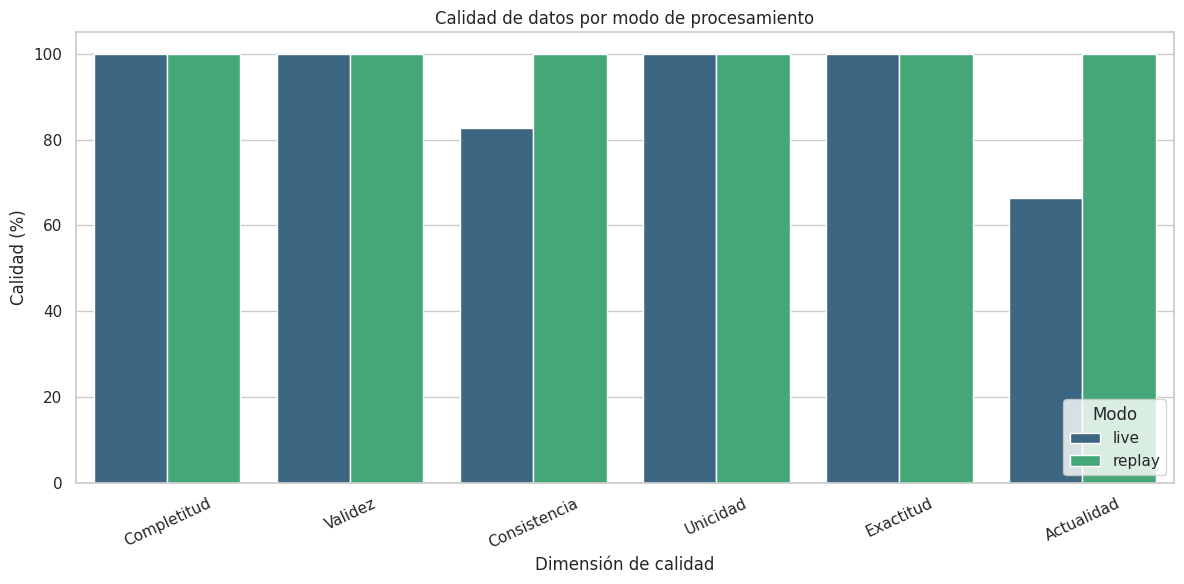

In [42]:
df_plot = (
    df_results
    .drop(index="Global")
    .drop(columns="Calidad global")
    .reset_index(names="Modo")
    .melt(
        id_vars="Modo",
        var_name="Dimensión",
        value_name="Calidad"
    )
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_plot,
    x="Dimensión",
    y="Calidad",
    hue="Modo",
    palette="viridis"
)

plt.title("Calidad de datos por modo de procesamiento")
plt.ylabel("Calidad (%)")
plt.xlabel("Dimensión de calidad")
plt.ylim(0, 105)

plt.xticks(rotation=25)
plt.legend(title="Modo", loc="lower right")

plt.tight_layout()
plt.show()

### Mensajes excluidos por el consumidor
Ahora vamos a analizar que ocurre en la tabla de cuarentena, estableciendo tasas de rechazo (mensajes invalidos), exclusion (eventos que llegan y no son terremotos) lo cual indicaria que el productor falla al filtrar algunos de estos eventos. Así mismo analizaremos el motivo de rechazo mas frecuente, y las diferencias entre modo live y replay

In [44]:
# Obtenemos la tabla de cuarentena
query_quarantine = """
SELECT *
FROM consumer_quarantine
"""

with engine.connect() as conn:
    quarantine = pd.read_sql(
        text(query_quarantine), conn
    )

print("Registros en cuarentena:", len(quarantine))

display(quarantine.head())

Registros en cuarentena: 0


,id,event_id,mode,reason,original_message,created_at


En estos momentos la tabla de cuarentena esta vacía lo cual es un indicativo de que los mensajes llegan con la estructura y datos correctos. Habrá que ir analizando su evolución en el tiempo para ver como evoluciona el sistema

# Conclusiones finales

Tanto el productor como el consumidor presentan muy buenos rendimientos en todas sus metricas. De especial atención serían las mejoras propuestas para la base de datos, en especial las tablas del prodcutor, de cara a analisis futuros. También es conveniente monitorear en el tiempo la tabla de cuarentena del consumidor y analizar porque hay registros en modo live con incosistencia de procesamiento.

En general el servicio es robusto e idempotente así como rápido.

Como muchos mensajes no validos como explosiones, roturas de hielo y demás se filtran en el productor su coste es bastante más bajo que si hiciesemos ese filtrado en el consumidor, ya que estariamos publicando en kafka mensajes que ya sabemos que son invalidos, lo cual podria llevar a sobre costes en el dimensionamiento de los brokers de kafka.